# Model comparison: which model goes to the holdout, and where forecasts fail

Everything here reads the saved backtest (26 weekly origins, 16 Apr to 8 Oct 2011). Nothing is
refitted and the holdout is not touched. Run `python -m demand.backtest --statistical` and
`--add lightgbm lightgbm_no_christmas lightgbm_products_only` first.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if Path.cwd().name == "notebooks":
    os.chdir("..")

from demand import data
from demand.backtest import summarise
from demand.clean import clean
from demand.compare import (
    combine,
    error_on_flagged_days,
    large_order_days,
    paired_difference,
    wmape_by_series,
)
from demand.eda import before_holdout, demand_classes
from demand.series import TOTAL

FIG = Path("reports/figures")
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
BLUE, ORANGE, GREEN, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29e"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": GRID,
        "axes.labelcolor": MUTED,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.titlelocation": "left",
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "savefig.dpi": 150,
        "savefig.bbox": "tight",
    }
)

results = pd.read_parquet(data.data_dir() / "processed" / "backtest_results.parquet")
results = pd.concat([results, combine(results, ["ets", "lightgbm"], "ets_lgbm_mean")])
products = results[results["series"] != TOTAL]
total = results[results["series"] == TOTAL]
sorted(results["model"].unique())

['ets',
 'ets_lgbm_mean',
 'ets_log',
 'lightgbm',
 'lightgbm_no_christmas',
 'lightgbm_products_only',
 'naive',
 'seasonal_naive',
 'weekday_mean_4']

## Every model on one table

In [2]:
summary = summarise(results)
table = pd.DataFrame(
    {
        model: {
            "products wMAPE": s["products"]["wmape"],
            "median per product": s["products"]["median_product_wmape"],
            "products bias": s["products"]["bias"],
            "total wMAPE": s["total"]["wmape"],
            "total bias": s["total"]["bias"],
        }
        for model, s in summary.items()
    }
).T.sort_values("products wMAPE")
table.round(3)

,products wMAPE,median per product,products bias,total wMAPE,total bias
ets_log,0.775,0.843,-0.482,0.302,-0.080
lightgbm_no_christmas,0.881,0.960,-0.028,0.304,-0.027
lightgbm_products_only,0.890,0.958,-0.016,0.336,-0.011
lightgbm,0.891,0.959,-0.012,0.321,-0.012
ets_lgbm_mean,0.901,0.953,0.010,0.303,-0.022
ets,0.939,0.974,0.033,0.307,-0.031
weekday_mean_4,0.998,1.049,-0.007,0.319,-0.066
naive,1.117,1.068,-0.074,0.382,-0.159
seasonal_naive,1.175,1.233,0.021,0.378,-0.020


ETS on log units is lowest but forecasts half the units (decision 23), so it's out. The rest
are within a few hundredths of each other. Picking the smallest number would be picking noise.

## Are the differences real?

Each model minus ETS, origin by origin, with a 95% bootstrap interval that resamples whole
origins (days inside one origin's 14-day window are not independent).

In [3]:
candidates = ["weekday_mean_4", "lightgbm", "lightgbm_no_christmas", "lightgbm_products_only",
              "ets_lgbm_mean"]  # fmt: skip
paired = pd.DataFrame(
    {
        (level, m): paired_difference(part, m, "ets")
        for level, part in (("products", products), ("total", total))
        for m in candidates
    }
).T
paired.round(3)

difference    low   high  origins_a_better  \
products weekday_mean_4               0.059  0.030  0.087               3.0   
         lightgbm                    -0.048 -0.084 -0.015              17.0   
         lightgbm_no_christmas       -0.058 -0.086 -0.035              23.0   
         lightgbm_products_only      -0.049 -0.085 -0.014              18.0   
         ets_lgbm_mean               -0.037 -0.056 -0.020              20.0   
total    weekday_mean_4               0.012 -0.008  0.032              10.0   
         lightgbm                     0.014 -0.008  0.038              15.0   
         lightgbm_no_christmas       -0.003 -0.014  0.009              13.0   
         lightgbm_products_only       0.029  0.007  0.050               9.0   
         ets_lgbm_mean               -0.004 -0.015  0.007              17.0   

                                 origins  
products weekday_mean_4             26.0  
         lightgbm                   26.0  
         lightgbm_no_christmas      26.0  
         lightgbm_products_only     26.0  
         ets_lgbm_mean              26.0  
total    weekday_mean_4             26.0  
         lightgbm                   26.0  
         lightgbm_no_christmas      26.0  
         lightgbm_products_only     26.0  
         ets_lgbm_mean              26.0

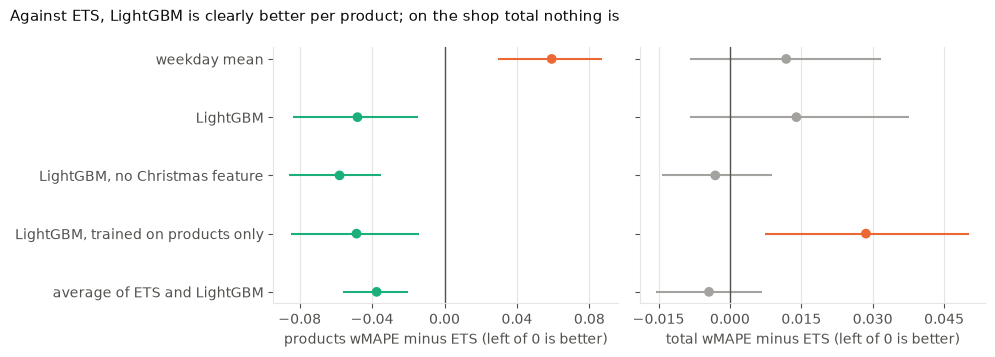

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
labels = {
    "weekday_mean_4": "weekday mean",
    "lightgbm": "LightGBM",
    "lightgbm_no_christmas": "LightGBM, no Christmas feature",
    "lightgbm_products_only": "LightGBM, trained on products only",
    "ets_lgbm_mean": "average of ETS and LightGBM",
}
y = np.arange(len(candidates))[::-1]
for ax, level in zip(axes, ("products", "total"), strict=True):
    part = paired.loc[level].loc[candidates]
    color = [GREEN if h < 0 else (ORANGE if lo > 0 else GRAY)
             for lo, h in zip(part["low"], part["high"], strict=True)]  # fmt: skip
    ax.errorbar(part["difference"], y, xerr=[part["difference"] - part["low"],
                part["high"] - part["difference"]], fmt="none", ecolor=color, lw=1.5)  # fmt: skip
    ax.scatter(part["difference"], y, c=color, zorder=3)
    ax.axvline(0, color=MUTED, lw=1)
    ax.set_xlabel(f"{level} wMAPE minus ETS (left of 0 is better)")
    ax.grid(axis="x", color=GRID)
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
axes[0].set_yticks(y, [labels[m] for m in candidates])
fig.suptitle(
    "Against ETS, LightGBM is clearly better per product; on the shop total nothing is",
    x=0.01, ha="left", color=INK, fontsize=11,
)  # fmt: skip
fig.tight_layout()
fig.savefig(FIG / "compare_vs_ets.png")

- **Products:** LightGBM without the Christmas feature beats ETS at 23 of 26 origins; the whole
  interval is below 0. With or without that feature is within noise per product.
- **Shop total:** nothing beats ETS for sure, and ETS itself doesn't clearly beat the weekday
  mean there (next cell). Training LightGBM on products only is clearly worse on the total.

In [5]:
pd.Series(paired_difference(total, "ets", "weekday_mean_4")).round(3)

difference          -0.012
low                 -0.032
high                 0.008
origins_a_better    16.000
origins             26.000
dtype: float64

**Dead end, kept:** the weeks-to-Christmas feature carried 21% of LightGBM's gain on Day 7, so it
looked important. Dropped, the products score didn't change within noise and the total got a
little better (0.321 to 0.304). It was learning the one autumn in the training data, not a rule.
High importance didn't mean useful.

In [6]:
pd.Series(paired_difference(total, "lightgbm_no_christmas", "lightgbm")).round(3)

difference          -0.017
low                 -0.042
high                 0.007
origins_a_better    16.000
origins             26.000
dtype: float64

## Where the forecasts fail

### Large-order days

In [7]:
sales, _ = clean(data.load())
flagged = error_on_flagged_days(
    products[products["model"].isin(["weekday_mean_4", "ets", "lightgbm_no_christmas"])],
    large_order_days(sales),
)
flagged.round(3)

,flagged_share_of_days,flagged_share_of_units,flagged_share_of_error
ets,0.022,0.234,0.211
lightgbm_no_christmas,0.022,0.234,0.226
weekday_mean_4,0.022,0.234,0.201


Product-days with a large order are 2% of days and 23% of units, and they carry about the same
share of the error. They hurt in proportion, not out of proportion: no model predicts them,
but the ordinary days are noisy too.

### Which products

In [8]:
per_product = wmape_by_series(products)["lightgbm_no_christmas"].rename("wmape")
traits = demand_classes(
    before_holdout(pd.read_parquet(data.data_dir() / "processed" / "daily_units.parquet"))
)
level = (
    before_holdout(pd.read_parquet(data.data_dir() / "processed" / "daily_units.parquet"))
    .drop(columns=TOTAL)
    .mean()
)
by_product = traits.join(per_product).assign(level=level)
by_product[["wmape", "cv2", "adi", "level"]].corr(method="spearman").round(2)["wmape"]

wmape    1.00
cv2      0.51
adi      0.74
level   -0.62
Name: wmape, dtype: float64

Rank correlation with each product's backtest wMAPE: how often it sells (ADI) matters most,
then its level, then how much its amounts swing. The worst products sell little and not every day.

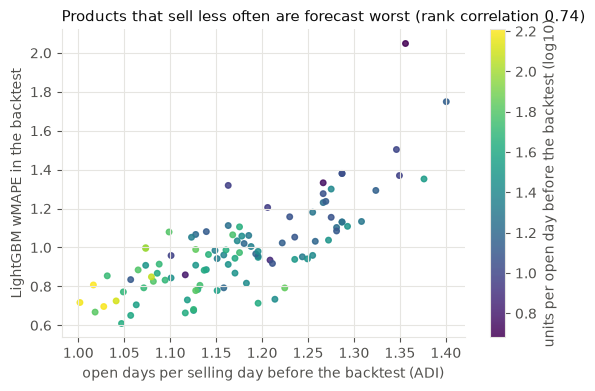

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 4))
sc = ax.scatter(by_product["adi"], by_product["wmape"], s=16, c=np.log10(by_product["level"]),
                cmap="viridis", alpha=0.85)  # fmt: skip
cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("units per open day before the backtest (log10)", color=MUTED)
ax.set_xlabel("open days per selling day before the backtest (ADI)")
ax.set_ylabel("LightGBM wMAPE in the backtest")
ax.grid(color=GRID)
rho = by_product[["wmape", "adi"]].corr(method="spearman").iloc[0, 1]
ax.set_title(f"Products that sell less often are forecast worst (rank correlation {rho:.2f})")
fig.savefig(FIG / "compare_by_product.png")

In [10]:
by_product.sort_values("wmape")[["wmape", "cv2", "adi", "level"]].round(2).iloc[
    [0, 1, 2, -3, -2, -1]
]

,wmape,cv2,adi,level
20727,0.61,3.46,1.05,42.51
20728,0.65,3.84,1.06,39.33
22383,0.66,1.52,1.12,42.32
22196,1.50,1.89,1.35,10.16
85150,1.75,2.27,1.40,13.90
21217,2.05,2.45,1.36,4.79


## Pick for the holdout

**LightGBM without the weeks-to-Christmas feature**, for products and the shop total, scored
once on the holdout alongside ETS and the weekday mean as references.

- Per product it beats ETS clearly (23 of 26 origins) with -3% bias.
- On the total it ties with ETS and the weekday mean; one model for both keeps the pipeline simple.
- The backtest's 26 origins mostly miss the autumn peak, and every model under-forecast September.
  Expect the holdout error to be higher than these numbers.